# Interpretable Machine Learning for Wine Quality Prediction

## Packages

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn import metrics
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import normaltest
import scipy.stats as stats
import math
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.metrics import r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.stats import randint
import shap

import warnings
warnings.filterwarnings('ignore')

## dataset

In [3]:
df = pd.read_csv(r"C:\Users\clair\OneDrive\Desktop\winequality.csv")

## checking and filling in missing values

## checking for missing values

In [6]:
missing_values = df.isnull().sum()
total_missing = df.isnull().sum().sum()
print(missing_values[missing_values > 0])
print(total_missing)

fixed acidity       10
volatile acidity     8
citric acid          3
residual sugar       2
chlorides            2
pH                   9
sulphates            4
dtype: int64
38


## impution method

In [8]:
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

def detect_outliers_iqr(df, columns):
    outlier_indices = {}
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        outlier_indices[col] = outliers.index.tolist()
    return outlier_indices

iqr_outliers = detect_outliers_iqr(df, numeric_cols)

for col, outliers in iqr_outliers.items():
    print(f"{col}: {len(outliers)} outliers")

fixed acidity: 357 outliers
volatile acidity: 376 outliers
citric acid: 508 outliers
residual sugar: 118 outliers
chlorides: 286 outliers
free sulfur dioxide: 62 outliers
total sulfur dioxide: 10 outliers
density: 3 outliers
pH: 73 outliers
sulphates: 191 outliers
alcohol: 3 outliers
quality: 228 outliers


## impute missing valuse (median)

In [10]:
df.fillna(df.median(numeric_only=True), inplace=True)

## understanding the dataset

#### view first 5 lines of each feature

In [13]:
print(df.head())

    type  fixed acidity  volatile acidity  citric acid  residual sugar  \
0  white            7.0              0.27         0.36            20.7   
1  white            6.3              0.30         0.34             1.6   
2  white            8.1              0.28         0.40             6.9   
3  white            7.2              0.23         0.32             8.5   
4  white            7.2              0.23         0.32             8.5   

   chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  \
0      0.045                 45.0                 170.0   1.0010  3.00   
1      0.049                 14.0                 132.0   0.9940  3.30   
2      0.050                 30.0                  97.0   0.9951  3.26   
3      0.058                 47.0                 186.0   0.9956  3.19   
4      0.058                 47.0                 186.0   0.9956  3.19   

   sulphates  alcohol  quality  
0       0.45      8.8        6  
1       0.49      9.5        6  
2       0.4

#### view feature characteristics

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   object 
 1   fixed acidity         6497 non-null   float64
 2   volatile acidity      6497 non-null   float64
 3   citric acid           6497 non-null   float64
 4   residual sugar        6497 non-null   float64
 5   chlorides             6497 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6497 non-null   float64
 10  sulphates             6497 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


#### features description

In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.216246,1.295779,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339630,0.164557,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318718,0.145231,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443574,4.757585,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056039,0.035031,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218384,0.160637,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531202,0.148769,0.22000,0.43000,0.51000,0.60000,2.00000


#### Feature Distribution

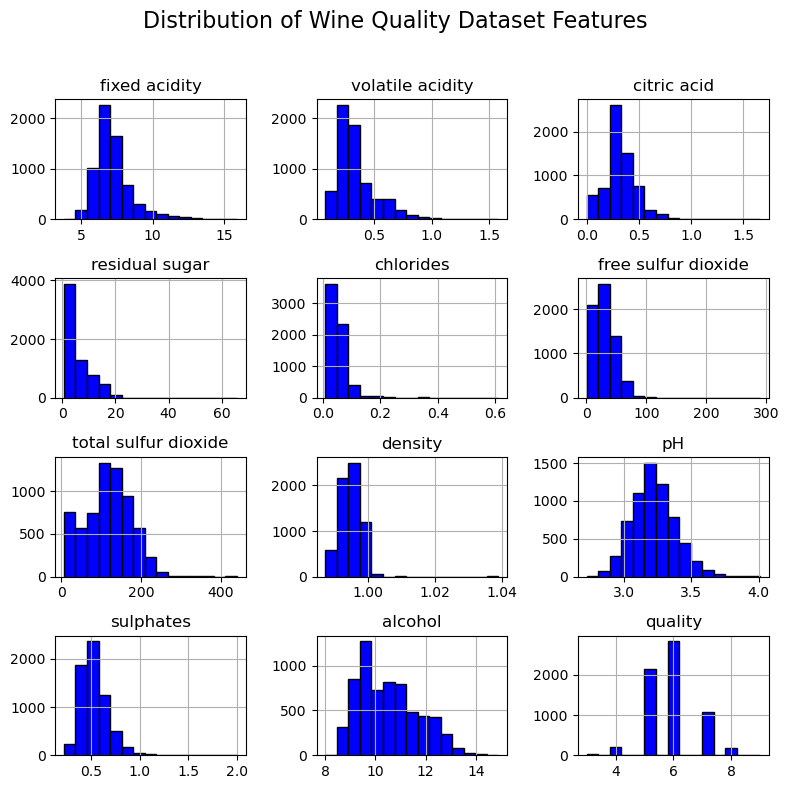

In [18]:
df.hist(figsize=(8, 8), bins=15, color='blue', edgecolor='black')
plt.suptitle('Distribution of Wine Quality Dataset Features', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#### barplot of quality by alcohol

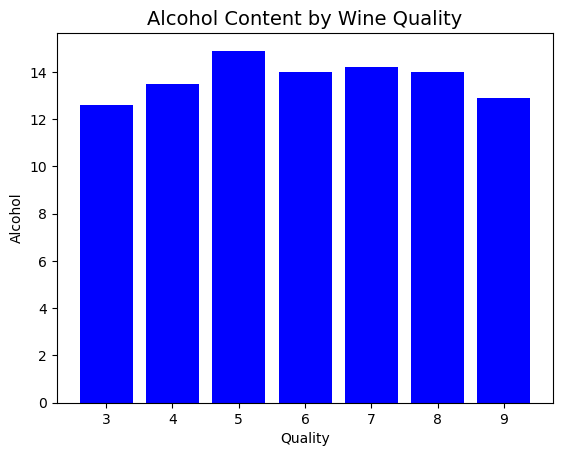

In [19]:
plt.bar(df['quality'], df['alcohol'], color='blue')
plt.xlabel('Quality')
plt.ylabel('Alcohol')
plt.title('Alcohol Content by Wine Quality', fontsize=14)
plt.show()

## preparing dataset

#### Feature Correlation Matrix

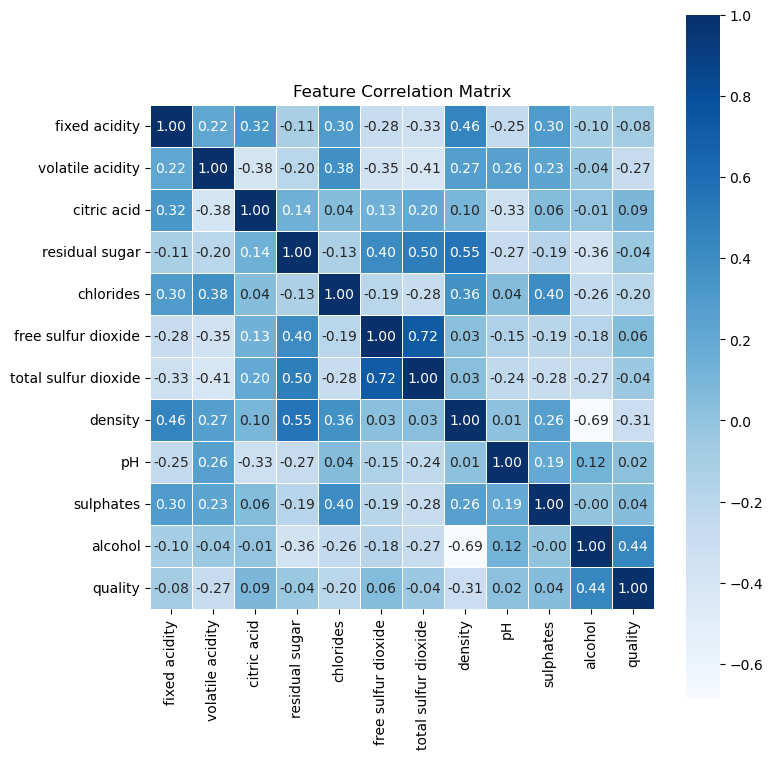

In [22]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(8, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", square=True, linewidths=0.5)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

#### test to see which var is more important

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np

X_free = df[['free sulfur dioxide']]
X_total = df[['total sulfur dioxide']]
y = df['quality']

model = LinearRegression()

model.fit(X_free, y)
y_pred_free = model.predict(X_free)
r2_free = r2_score(y, y_pred_free)

model.fit(X_total, y)
y_pred_total = model.predict(X_total)
r2_total = r2_score(y, y_pred_total)

print(f"R² score for free sulfur dioxide: {r2_free:.4f}")
print(f"R² score for total sulfur dioxide: {r2_total:.4f}")

R² score for free sulfur dioxide: 0.0031
R² score for total sulfur dioxide: 0.0017


#### drop sulfur dioxide

In [25]:
# drop total sulfer dioxide since there is direct correlation as seen in the heat map
df = df.drop('total sulfur dioxide', axis=1)

In [26]:
df['best quality'] = [1 if x > 5 else 0 for x in df.quality]

#### make wine type (white or red) binary

In [28]:
df.replace({'white': 1, 'red': 0}, inplace=True)

In [29]:
features = df.drop(['quality', 'best quality'], axis=1)
target = df['best quality']

features = features.fillna(features.mean())

xtrain, xtest, ytrain, ytest = train_test_split(
    features, target, test_size=0.2, random_state=40)

imputer = SimpleImputer(strategy='mean')
xtrain = imputer.fit_transform(xtrain)
xtest = imputer.transform(xtest)

xtrain.shape, xtest.shape

((5197, 11), (1300, 11))

## test initial models

#### scale training and testing model

In [30]:
norm = MinMaxScaler()
xtrain = norm.fit_transform(xtrain)
xtest = norm.transform(xtest)

#### Logistic Regression Model

In [31]:
log_model = LogisticRegression()
log_model.fit(xtrain, ytrain)

print('Training Model:', metrics.roc_auc_score(ytrain, log_model.predict(xtrain)))
print('Testing Accuracy:', metrics.roc_auc_score(ytest, log_model.predict(xtest)))

Training Model: 0.7027810651830071
Testing Accuracy: 0.6949995402580684


#### XGBoost model

In [33]:
xgb_model = XGBClassifier()
xgb_model.fit(xtrain, ytrain)

print('Training Accuracy:', metrics.roc_auc_score(ytrain, xgb_model.predict(xtrain)))
print('Testing Accuracy:', metrics.roc_auc_score(ytest, xgb_model.predict(xtest)))

Training Accuracy: 0.9805999996814359
Testing Accuracy: 0.806867522808308


#### svc model

In [34]:
svc_model = SVC(kernel='rbf', probability=True)
svc_model.fit(xtrain, ytrain)

print('Training Accuracy:', metrics.roc_auc_score(ytrain, svc_model.predict(xtrain)))
print('Testing Accuracy:', metrics.roc_auc_score(ytest, svc_model.predict(xtest)))

Training Accuracy: 0.7082288310128588
Testing Accuracy: 0.6964017531492322


## test for other models

#### quality histogram

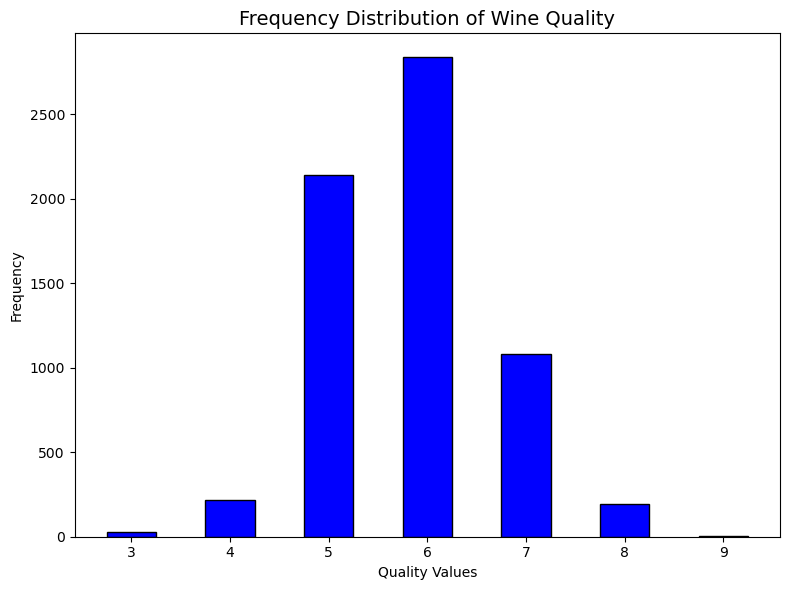

In [35]:
quality = df['quality']
frequency = quality.value_counts().sort_index()
plt.figure(figsize=(8, 6))
plt.bar(frequency.index, frequency.values, color='blue', edgecolor='black', width=0.5)
plt.xlabel('Quality Values')
plt.ylabel('Frequency')
plt.title('Frequency Distribution of Wine Quality', fontsize=14)
plt.tight_layout()
plt.show()


In [ ]:
based on this histogram we can see our dataset is imbalanced. There are less datapoints for quality 3,4,8, and 9 with signifigant amounts of datapoints for quality 5,6, and 7.

#### Methods used for box plots and Q-Q plots

In [36]:
import scipy.stats as stats
import math

def quantile_plot(columns, data):
    plt.rcParams['font.size'] = 7
    fig, axs = plt.subplots(2, len(columns) // 2)
    fig.set_size_inches(15, 8)
    fig.subplots_adjust(hspace = .5, wspace=.5)

    n = 0
    data = data[~np.isnan(data)]
    for i in range(0, 2):
        for j in range(0, len(columns) // 2):
            stats.probplot(data[columns[n]], dist="norm", plot=axs[i, j], fit=True)
            axs[i, j].set_title(f"Q-Q Plot of {columns[n].title()}")
            n += 1
    plt.show()

def box_plot(columns, data):
    plt.rcParams['font.size'] = 7
    fig, axs = plt.subplots(2, len(columns) // 2)
    fig.set_size_inches(15, 8)
    fig.subplots_adjust(hspace = .5, wspace=.5)

    n = 0
    data = data[~np.isnan(data)]
    for i in range(0, 2):
        for j in range(0, len(columns) // 2):
            axs[i, j].boxplot(data[columns[n]])
            axs[i, j].set_title(f"Q-Q Plot of {columns[n].title()}")
            n += 1
    plt.show()

#### Quality Q-Q plot

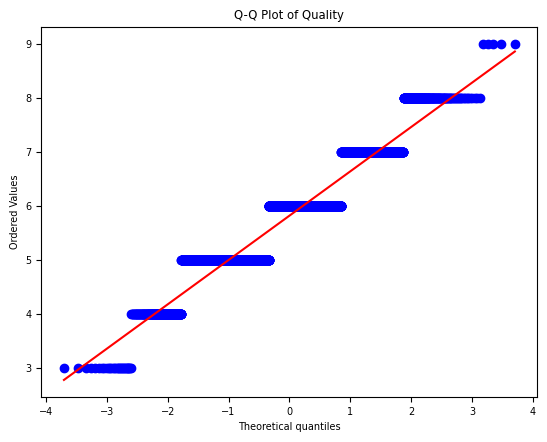

In [38]:
q = df['quality']
col = ['quality']

plt.rcParams['font.size'] = 7

stats.probplot(df['quality'], dist="norm", plot=plt, fit=True)
plt.title(f"Q-Q Plot of Quality")
plt.show()

#### Predictor Q-Q plots

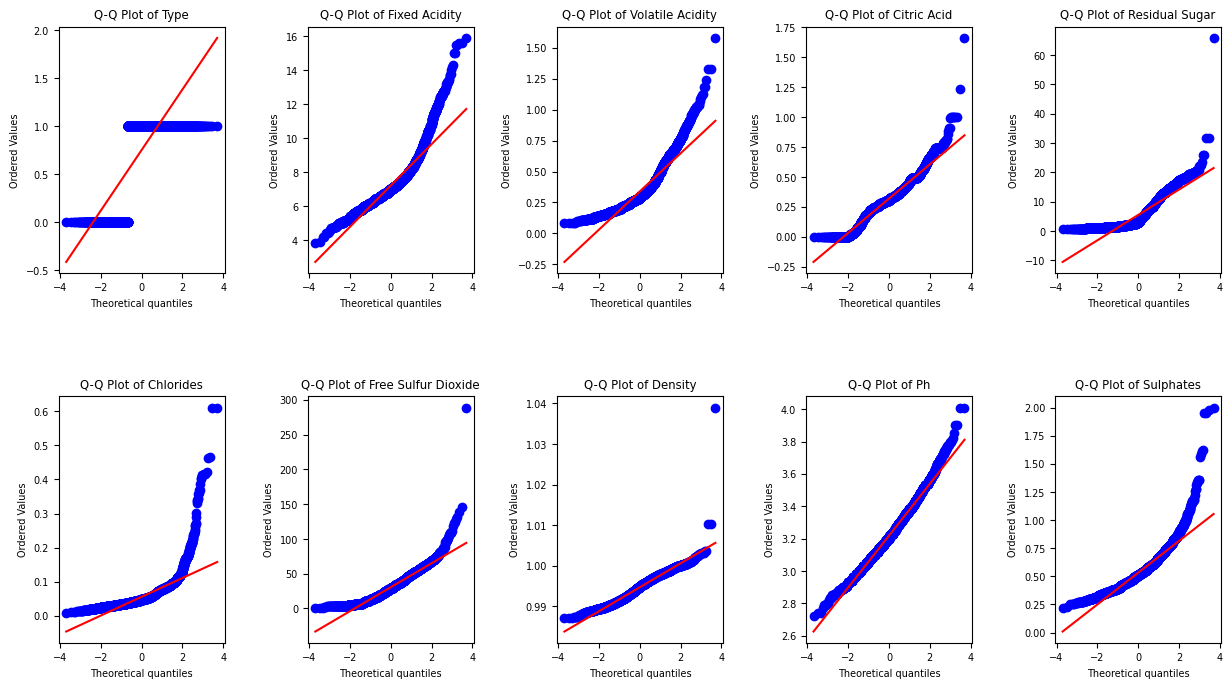

In [40]:
columns = features.columns

quantile_plot(columns, features)

#### D'Agostino and Pearson's Test

In [42]:
for col in list(features):
    statistic, p_value = normaltest(features[col])
    print(f"{col} P-value: {p_value}")

type P-value: 2.326352504273256e-261
fixed acidity P-value: 0.0
volatile acidity P-value: 0.0
citric acid P-value: 8.21655840260821e-129
residual sugar P-value: 0.0
chlorides P-value: 0.0
free sulfur dioxide P-value: 0.0
density P-value: 3.3988166443860096e-245
pH P-value: 9.978434011799395e-40
sulphates P-value: 0.0
alcohol P-value: 1.9599603946904556e-98


#### Boxplots of the predictors

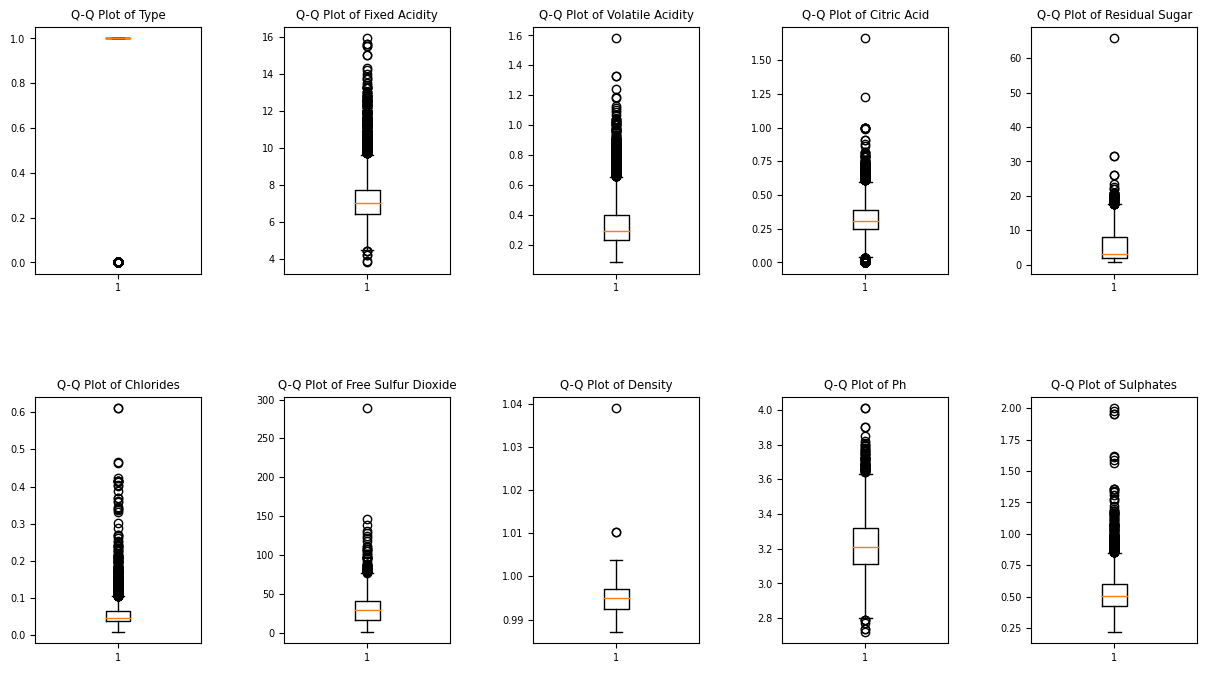

In [44]:
box_plot(columns, features)

In [ ]:
based on our testing, we have concluded that the random forest model is the best model for our dataset

## random forest model

#### orignial model, pre-SMOTE

In [47]:
# #X = df.drop('quality', axis=1)
#y = df['quality']
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# check number of samples
#print(Counter(y_train))
# merge quality 9 into 8
df['quality'] = df['quality'].replace(9, 8)
#rf = RandomForestClassifier(n_estimators=100, random_state=1)
#rf.fit(X_train, y_train)
#y_pred = rf.predict(X_test)
#print("Accuracy:", accuracy_score(y_test, y_pred))
#print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
#print("\nClassification Report:\n", classification_report(y_test, y_pred))

#### Heatmap for the Confusion Matrix, pre-SMOTE

In [49]:
# matrix = {
#     '3': [0, 0, 2, 0, 0, 0],
#     '4': [1, 18, 19, 6, 2, 0],
#     '5': [1, 14, 320, 81, 4, 0],
#     '6': [0, 4, 104, 387, 79, 5],
#     '7': [0, 2, 6, 64, 141, 8],
#     '8': [0, 0, 0, 10, 14, 8]
# }
# df_cm = pd.DataFrame(matrix)
# 
# plt.figure(figsize=(6, 6))
# sb.heatmap(df_cm, annot=True, cbar=True, linewidths=0.5, linecolor='white', yticklabels=['3', '4', '5', '6', '7', '8'], fmt='d', annot_kws={"size": 12})
# plt.title("Heatmap of the Baseline Confusion Matrix")
# plt.xlabel("Amount of Predictions by Category")
# plt.ylabel("Amount of True Values by Quality")
# plt.show()

#### random forest model using SMOTE

In [50]:
df['type'] = df['type'].map({'red': 0, 'white': 1})

X = df.drop('quality', axis=1)
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

# impute
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Apply SMOTE to imputed data
smote = SMOTE(random_state=1)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_imputed, y_train)

# train rfm
rf = RandomForestClassifier(n_estimators=100, random_state=1)
rf.fit(X_train_resampled, y_train_resampled)

y_pred = rf.predict(X_test_imputed)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.813076923076923

Confusion Matrix:
 [[  0   2   4   0   0   0]
 [  1  20  22   0   0   0]
 [  5  38 385   0   0   0]
 [  0   0   0 489  67  11]
 [  0   0   0  58 145  13]
 [  0   0   0  11  11  18]]

Classification Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.33      0.47      0.39        43
           5       0.94      0.90      0.92       428
           6       0.88      0.86      0.87       567
           7       0.65      0.67      0.66       216
           8       0.43      0.45      0.44        40

    accuracy                           0.81      1300
   macro avg       0.54      0.56      0.55      1300
weighted avg       0.82      0.81      0.82      1300



#### hyperparmeter training

In [51]:
df['type'] = df['type'].map({'red': 0, 'white': 1})

X = df.drop('quality', axis=1)
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

# pipeline with imputer, SMOTE, and RandomForest
pipeline = ImbPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('smote', SMOTE(random_state=1)),
    ('rf', RandomForestClassifier(random_state=1))])

# hyperparameter search space
param_dist = {
    'rf__n_estimators': randint(50, 300),
    'rf__max_depth': [None] + list(range(5, 30, 5)),
    'rf__min_samples_split': randint(2, 10),
    'rf__min_samples_leaf': randint(1, 5),
    'rf__max_features': ['auto', 'sqrt', 'log2']
}

# random search with 5-fold cross-validation
random_search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring='accuracy',
    cv=5,
    verbose=2,
    random_state=1,
    n_jobs=1)

random_search.fit(X_train, y_train)

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)

print("Best Parameters:", random_search.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END rf__max_depth=25, rf__max_features=auto, rf__min_samples_leaf=1, rf__min_samples_split=9, rf__n_estimators=187; total time=   0.0s
[CV] END rf__max_depth=25, rf__max_features=auto, rf__min_samples_leaf=1, rf__min_samples_split=9, rf__n_estimators=187; total time=   0.0s
[CV] END rf__max_depth=25, rf__max_features=auto, rf__min_samples_leaf=1, rf__min_samples_split=9, rf__n_estimators=187; total time=   0.0s
[CV] END rf__max_depth=25, rf__max_features=auto, rf__min_samples_leaf=1, rf__min_samples_split=9, rf__n_estimators=187; total time=   0.0s
[CV] END rf__max_depth=25, rf__max_features=auto, rf__min_samples_leaf=1, rf__min_samples_split=9, rf__n_estimators=187; total time=   0.0s
[CV] END rf__max_depth=15, rf__max_features=sqrt, rf__min_samples_leaf=4, rf__min_samples_split=2, rf__n_estimators=194; total time=  10.8s
[CV] END rf__max_depth=15, rf__max_features=sqrt, rf__min_samples_leaf=4, rf__min_samples_split=2,

#### heatmap for hyperparametic model

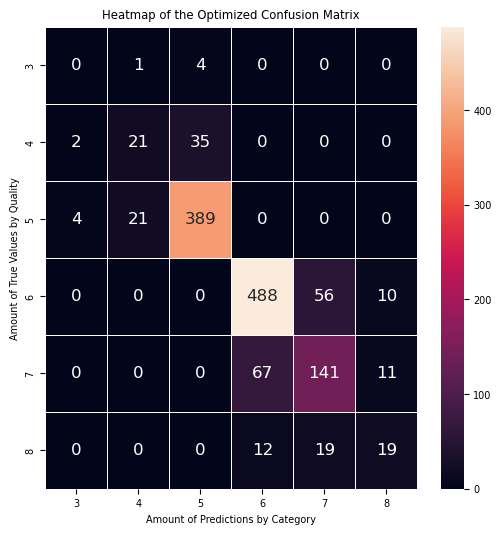

In [52]:
matrix = {
    '3': [0, 2, 4, 0, 0, 0],
    '4': [1, 21, 21, 0, 0, 0],
    '5': [4, 35, 389, 0, 0, 0],
    '6': [0, 0, 0, 488, 67, 12],
    '7': [0, 0, 0, 56, 141, 19],
    '8': [0, 0, 0, 10, 11, 19]
}
df_cm = pd.DataFrame(matrix)

plt.figure(figsize=(6, 6))
sb.heatmap(df_cm, annot=True, cbar=True, linewidths=0.5, linecolor='white', yticklabels=['3', '4', '5', '6', '7', '8'], fmt='d', annot_kws={"size": 12})
plt.title("Heatmap of the Optimized Confusion Matrix")
plt.xlabel("Amount of Predictions by Category")
plt.ylabel("Amount of True Values by Quality")
plt.show()

## permutation importance method

               Feature  Importance Mean  Importance Std
9              alcohol         0.137354        0.007516
1     volatile acidity         0.083692        0.005566
6              density         0.033785        0.008511
5  free sulfur dioxide         0.025662        0.005030
8            sulphates         0.024185        0.007113
3       residual sugar         0.019262        0.004703
4            chlorides         0.018031        0.004581
2          citric acid         0.012185        0.004279
7                   pH         0.011323        0.005288
0        fixed acidity         0.006585        0.003599


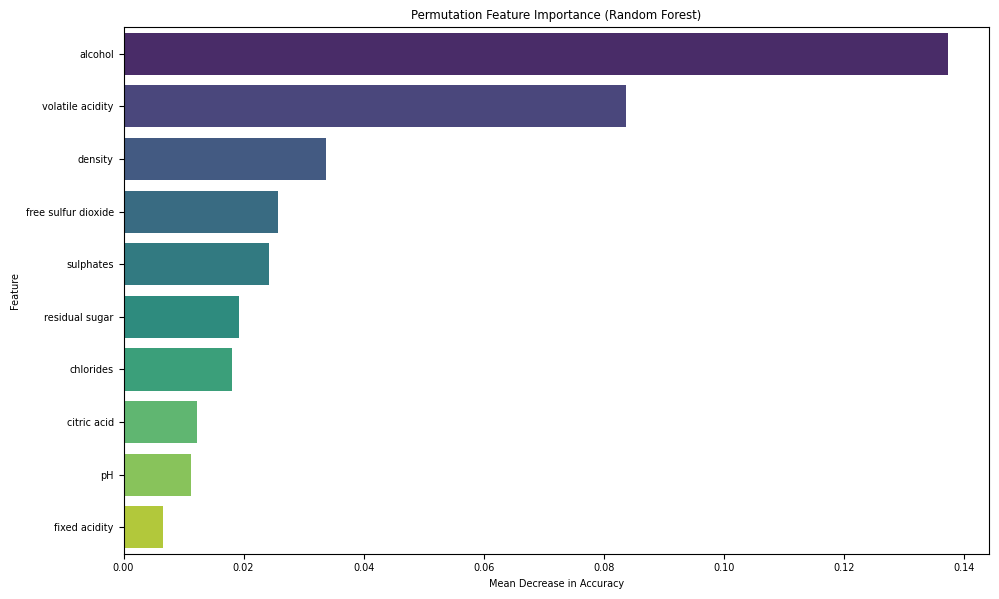

In [54]:
# drop variables quality and type
X = df.drop(columns=['quality', 'best quality', 'type'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# Fit  RFM
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

result = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42, n_jobs=1)

perm_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance Mean': result.importances_mean,
    'Importance Std': result.importances_std
}).sort_values(by='Importance Mean', ascending=False)

print(perm_importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance Mean', y='Feature', data=perm_importance_df, palette='viridis')
plt.title("Permutation Feature Importance (Random Forest)")
plt.xlabel("Mean Decrease in Accuracy")
plt.tight_layout()
plt.show()


## Important features plot

#### 5 most important features that influence quality

In [57]:
feature_importances = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
})

feature_importances = feature_importances.sort_values(by='importance', ascending=False)
print(feature_importances.head(5))


               feature  importance
9              alcohol    0.130539
6              density    0.114371
1     volatile acidity    0.109039
8            sulphates    0.096809
5  free sulfur dioxide    0.096564


#### box plot of most important features

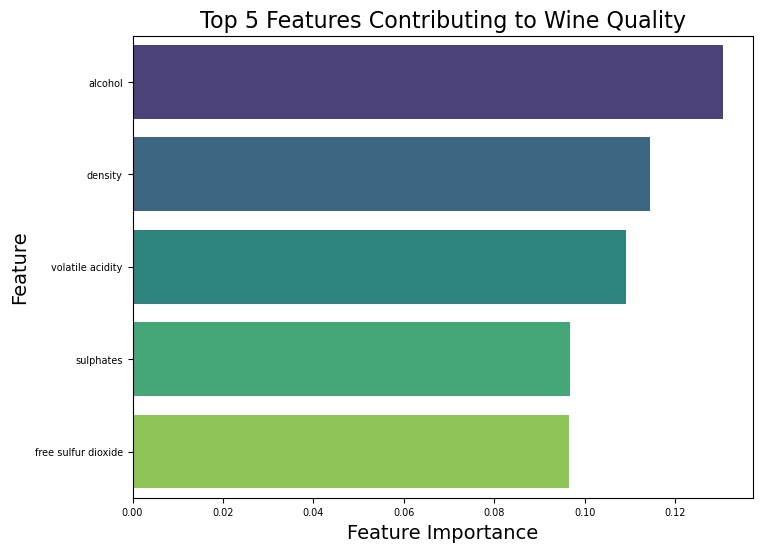

In [59]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x='importance', 
    y='feature', 
    data=feature_importances.head(5), 
    palette='viridis'
)

plt.title('Top 5 Features Contributing to Wine Quality', fontsize=16)
plt.xlabel('Feature Importance', fontsize=14)
plt.ylabel('Feature', fontsize=14)

plt.show()

#### importance per feature

In [61]:
correlation_matrix = df.corr()
sorted_correlations = correlation_matrix['quality'].abs().sort_values(ascending=False)

print(sorted_correlations)

quality                1.000000
best quality           0.816025
alcohol                0.444275
density                0.305735
volatile acidity       0.266400
chlorides              0.200565
citric acid            0.085527
fixed acidity          0.077279
free sulfur dioxide    0.055471
sulphates              0.039262
residual sugar         0.036796
pH                     0.018910
type                        NaN
Name: quality, dtype: float64


#### importance per feature plotted

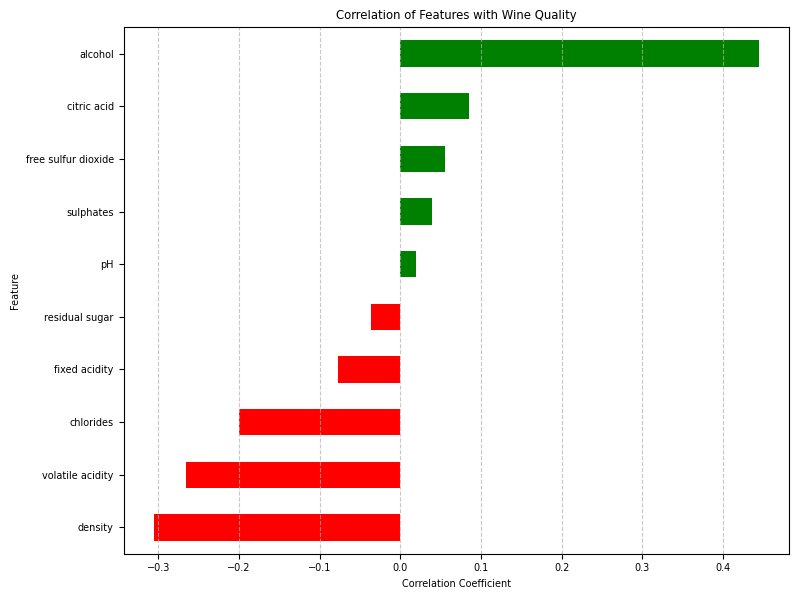

In [63]:
correlation_series = correlation_matrix['quality'].drop(['type', 'quality', 'best quality'], errors='ignore')
correlation_series = correlation_series.sort_values()

colors = ['red' if val < 0 else 'green' for val in correlation_series]

plt.figure(figsize=(8, 6))
correlation_series.plot(kind='barh', color=colors)

plt.title('Correlation of Features with Wine Quality')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Feature')
plt.grid(True, axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## SHAP

In [80]:
# Initialize SHAP explainer for Random Forest

explainer = shap.TreeExplainer(rf)  # rf_model is your trained Random Forest

shap_values = explainer.shap_values(X_test_imputed)
 
# For multiclass, shap_values will be a list of arrays (one per class)

#### Weighted summary plot

In [67]:
from collections import Counter
import numpy as np
 
class_counts = Counter(y_test)
class_order = sorted(class_counts.keys())  # ensure ordering matches shap_values
weights = np.array([class_counts[c] for c in class_order])
weights = weights / weights.sum()
 
# weighted mean over class axis
shap_values_all = np.tensordot(np.abs(shap_values), weights, axes=([2], [0]))  # shape: (1300, 11)

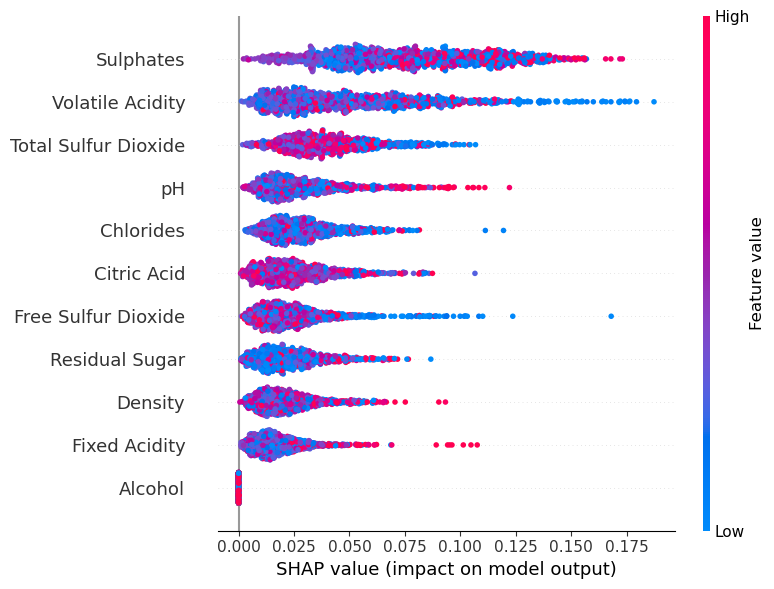

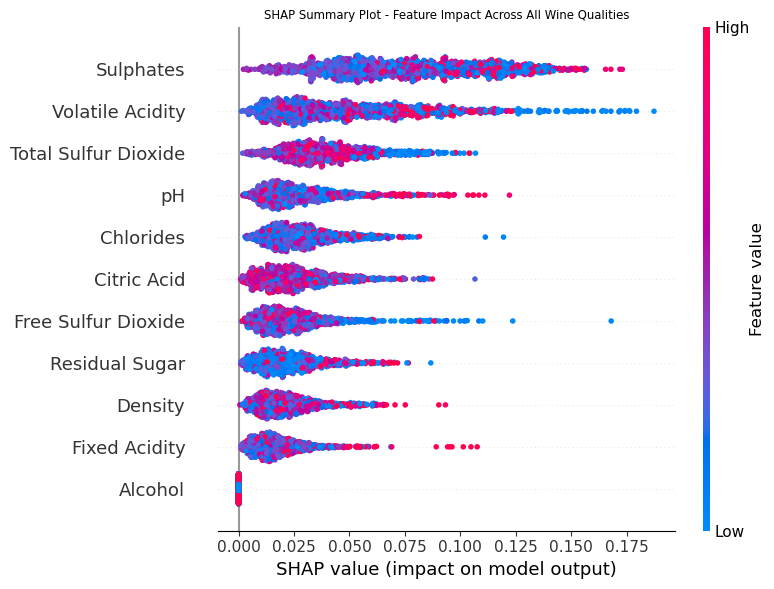

In [71]:
feature_names = [
    'Fixed Acidity',
    'Volatile Acidity',
    'Citric Acid',
    'Residual Sugar',
    'Chlorides',
    'Free Sulfur Dioxide',
    'Total Sulfur Dioxide',
    'Density',
    'pH',
    'Sulphates',
    'Alcohol'
]

class_names = ['Quality ' + str(i) for i in range(3, 9)]


# Compute class frequencies
from collections import Counter
import numpy as np
 
class_counts = Counter(y_test)
class_order = sorted(class_counts.keys())  # ensure ordering matches shap_values
weights = np.array([class_counts[c] for c in class_order])
weights = weights / weights.sum()
 
# weighted mean over class axis
shap_values_all = np.tensordot(np.abs(shap_values), weights, axes=([2], [0]))  # shape: (1300, 11)

# Compute average absolute SHAP value across classes
# shap_values_all = np.mean(np.abs(shap_values), axis=2)

# Plot the global feature importance
shap.summary_plot(shap_values_all, X_test_imputed, feature_names=feature_names)


plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_all, X_test_imputed, feature_names=feature_names, show=False)
plt.title('SHAP Summary Plot - Feature Impact Across All Wine Qualities')
plt.tight_layout()
plt.savefig('shap_summary_plot_all_qualities.png', dpi=300, bbox_inches='tight')
plt.show()

#### waterfall plot

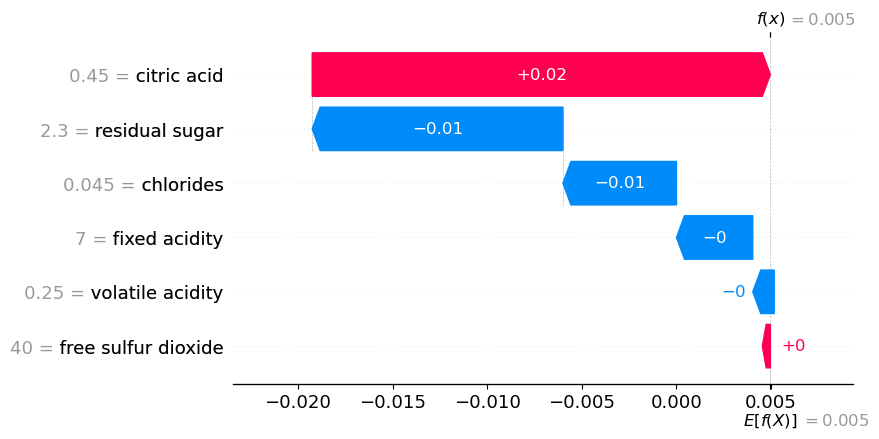

In [72]:
shap.initjs()

instance_to_explain = 0

class_to_explain = 0 

explanation_for_instance = shap.Explanation(
    values=shap_values[class_to_explain][instance_to_explain], 
    base_values=explainer.expected_value[class_to_explain],
    data=X_test.iloc[instance_to_explain], 
    feature_names=X_test.columns.tolist()
)

shap.waterfall_plot(explanation_for_instance, show=True)

#### Interaction Plot

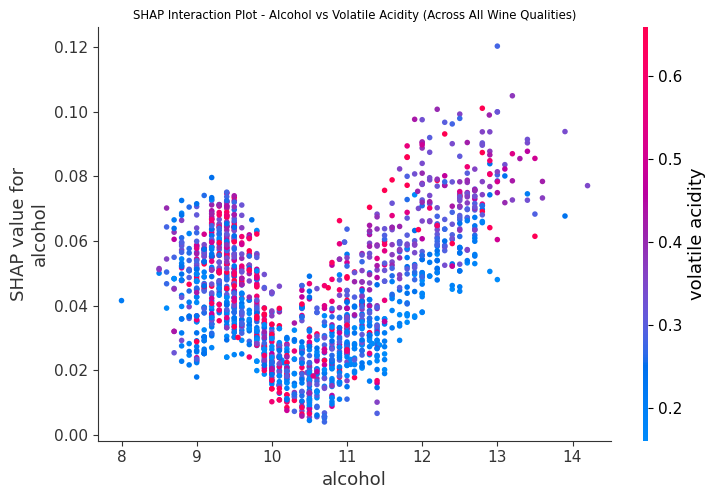

In [73]:
feature_names = X_test.columns.tolist()

try:
    recomputed_shap_values = explainer(X_test)
except NameError:
    print("Error: The `explainer` object is not defined. Please ensure you've run the code to create it.")
    recomputed_shap_values = None

if recomputed_shap_values is not None:
    # Collapse across classes: mean absolute SHAP values
    shap_values_all = np.mean(np.abs(recomputed_shap_values.values), axis=2)

    primary_feature_index = feature_names.index("alcohol")
    interaction_feature_index = feature_names.index("volatile acidity")

    shap.dependence_plot(
        primary_feature_index, 
        shap_values_all, 
        X_test, 
        feature_names=feature_names,
        interaction_index=interaction_feature_index, 
        show=False
    )

    plt.title('SHAP Interaction Plot - Alcohol vs Volatile Acidity (Across All Wine Qualities)')
    plt.tight_layout()
    plt.show()


## LIME

In [74]:
# LIME Analysis Implementation
from lime import lime_tabular

ModuleNotFoundError: No module named 'lime'

#### Initialize LIME explainer

In [ ]:
lime_explainer = lime_tabular.LimeTabularExplainer(

    X_train.values,
    feature_names=feature_names,
    class_names=['Quality' + str(i) for i in range(3,9)],
    mode='classification',
    discretize_continuous=True
)

In [ ]:
# Function to get model predictions in the format LIME expects
def predict_fn(data):
    return rf.predict_proba(data)

In [ ]:
# Generate explanations for sample predictions
sample_indices = [0, 50, 100]
 
for idx in sample_indices:
    # Generate explanation
    explanation = lime_explainer.explain_instance(
        X_test.iloc[idx].values,
        predict_fn,
        num_features=len(feature_names),
        top_labels=6
    )


In [ ]:
explanation.save_to_file(f'lime_explanation_sample_{idx}.html')

plt.figure(figsize=(8, 5))
plt.hist(df['alcohol'], bins=30, color='purple', edgecolor='black')
plt.title('Distribution of Alcohol Content in Wine')
plt.xlabel('Alcohol (%)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()